## ML-решение, построенное на бизнес-разборе

**Основа для анализа:** `analys_business_EDA.ipynb`

### Постановка задачи

| Вопрос | Ответ |
|---|---|
| Целевая переменная | Потребление следующего 15-минутного интервала, кВт·ч |
| Тип задачи | Регрессия |
| Основная метрика | MAE (устойчива к легитимным пикам) |
| Вспомогательные | RMSE, R², доля пойманных пиков, ошибка в деньгах |
| Исключены | `CO2(tCO2)` — утечка; `Load_Type` — 35,3% ошибок метки |
| Базлайн | Наивный прогноз: следующий интервал как текущий |

### План

| № | Шаг |
|---|---|
| 1 | Признаки из бизнес-разбора и проверка гипотез |
| 2 | Схема валидации и базлайны |
| 3 | Модели, гиперпараметры, кросс-валидация |
| 4 | Перевод качества модели в деньги и пики |
| 5 | Прогноз на будущий период для планировщика |
| 6 | Сценарный расчёт до 2030 года: три сценария и чувствительность |

## Шаг 1: Признаки и гипотезы

**Пояснения:**
- **Запаздывающие признаки (лаги)** и **скользящие статистики** — инерция
  оборудования: потребление следующего интервала близко к текущему и к уровню
  последнего часа; разброс за час — предвестник смены режима.
- **Циклическое кодирование часа** (синус/косинус) — суточная сезонность
  без разрыва между 23:45 и 00:15.
- **Календарь будущего легален:** тарифная зона и день недели следующего
  интервала известны заранее — это не утечка.
- **Гипотезы проверяем корреляцией** каждого признака с целью до обучения.

In [13]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
try:
    from catboost import CatBoostRegressor
    CATBOOST = True
except ImportError:
    CATBOOST = False
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.figsize': (13, 4.5), 'font.size': 11,
                     'axes.titlesize': 12, 'axes.labelsize': 11})
SEED = 42

def проверить(условие, сообщение):
    if not условие:
        raise AssertionError(f"ПРОВЕРКА НЕ ПРОЙДЕНА: {сообщение}")

def zone_of(dt):
    t = dt.hour*60 + dt.minute
    if (660 <= t < 720) or (780 <= t < 1020): return 'Пиковая'
    if (t >= 1380) or (t < 540):              return 'Ночная'
    return 'Полупиковая'
def season_of(m):
    return 'Лето' if m in (6,7,8) else ('Зима' if m in (11,12,1,2) else 'Весна_Осень')

df = pd.read_csv("Steel_industry_data.csv")
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M', dayfirst=True)
df = df.sort_values('date').reset_index(drop=True)

df['t_next'] = df['date'] + pd.Timedelta(minutes=15)
df['cur'] = df['Usage_kWh']
for lag in [1, 4, 96, 672]:
    df[f'lag_{lag}'] = df['Usage_kWh'].shift(lag)
df['roll_mean_4']  = df['Usage_kWh'].rolling(4).mean()
df['roll_std_4']   = df['Usage_kWh'].rolling(4).std()
df['roll_mean_96'] = df['Usage_kWh'].rolling(96).mean()
for col, src in [('hour', df['date']), ('hour_next', df['t_next'])]:
    h = src.dt.hour + src.dt.minute/60
    df[f'{col}_sin'] = np.sin(2*np.pi*h/24)
    df[f'{col}_cos'] = np.cos(2*np.pi*h/24)
df['zone_next']       = [zone_of(t) for t in df['t_next']]
df['season_next']     = [season_of(t.month) for t in df['t_next']]
df['is_weekend_next'] = (df['t_next'].dt.dayofweek >= 5).astype(int)
df['y'] = df['Usage_kWh'].shift(-1)
df = df.dropna().reset_index(drop=True)

FEATURES = ['cur','lag_1','lag_4','lag_96','lag_672',
            'roll_mean_4','roll_std_4','roll_mean_96',
            'hour_sin','hour_cos','hour_next_sin','hour_next_cos',
            'is_weekend_next','zone_next','season_next']
CAT = ['zone_next','season_next']
NUM = [f for f in FEATURES if f not in CAT]

проверить('CO2(tCO2)' not in FEATURES, "CO2 в признаках: утечка (бизнес-разбор, шаг 5)")
проверить('Load_Type' not in FEATURES, "Load_Type в признаках: 35,3% ошибок метки (шаг 4)")

corr = df[NUM + ['y']].corr()['y'].drop('y').sort_values(ascending=False)
по_зонам = df.groupby('zone_next')['y'].mean()
ГИП = {'cur':'инерция: якорь прогноза','lag_1':'инерция: предыдущий интервал',
       'lag_4':'инерция: час назад','lag_96':'суточный ритм','lag_672':'недельный ритм',
       'roll_mean_4':'текущий часовой уровень','roll_std_4':'неустойчивость нагрузки',
       'roll_mean_96':'суточный уровень','hour_next_sin':'суточная сезонность будущего'}
строк = "\n".join(f"| `{f}` | {corr.get(f, np.nan):.3f} | {ГИП.get(f,'календарь будущего')} |"
                  for f in corr.index)
display(Markdown(f"""
### Вывод по шагу 1: признаки готовы, утечек нет

- Таблица: **{len(df):,} наблюдений**, {len(FEATURES)} признаков.
- Утечки исключены проверками: CO₂ и метка нагрузки не входят в признаки;
  лаги и скользящие считаются только по прошлому; календарь будущего легален.

**Проверка гипотез о полезности признаков** (корреляция с целью):

| Признак | Корреляция | Гипотеза |
|---|---|---|
{строк}

Средняя цель по тарифным зонам следующего интервала, кВт·ч:
{', '.join(f'{z} — {v:.1f}' for z, v in по_зонам.items())}.
"""))


### Вывод по шагу 1: признаки готовы, утечек нет

- Таблица: **34,367 наблюдений**, 15 признаков.
- Утечки исключены проверками: CO₂ и метка нагрузки не входят в признаки;
  лаги и скользящие считаются только по прошлому; календарь будущего легален.

**Проверка гипотез о полезности признаков** (корреляция с целью):

| Признак | Корреляция | Гипотеза |
|---|---|---|
| `cur` | 0.912 | инерция: якорь прогноза |
| `roll_mean_4` | 0.843 | текущий часовой уровень |
| `lag_1` | 0.834 | инерция: предыдущий интервал |
| `lag_672` | 0.645 | недельный ритм |
| `lag_4` | 0.638 | инерция: час назад |
| `lag_96` | 0.577 | суточный ритм |
| `roll_std_4` | 0.543 | неустойчивость нагрузки |
| `roll_mean_96` | 0.353 | суточный уровень |
| `hour_sin` | -0.276 | календарь будущего |
| `is_weekend_next` | -0.294 | календарь будущего |
| `hour_next_sin` | -0.307 | суточная сезонность будущего |
| `hour_next_cos` | -0.451 | календарь будущего |
| `hour_cos` | -0.470 | календарь будущего |

Средняя цель по тарифным зонам следующего интервала, кВт·ч:
Ночная — 8.6, Пиковая — 52.7, Полупиковая — 34.2.


## Шаг 2: Схема валидации и базлайны

**Пояснения:**
- **Хронологический сплит 80/20:** обучение на начале года, проверка на конце.
- **MAE** — средняя абсолютная ошибка: редкие пики не искажают метрику.
- **RMSE** — штрафует большие ошибки сильнее: индикатор качества на пиках.
- **R²** — доля объяснённой дисперсии.
- **Наивный базлайн:** «следующий интервал как текущий» — точка отсчёта.

In [14]:
def метрики(y_true, y_pred):
    return (mean_absolute_error(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            r2_score(y_true, y_pred))

def конвейер(модель):
    pre = ColumnTransformer([('num', StandardScaler(), NUM),
                             ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])
    return Pipeline([('pre', pre), ('model', модель)])

граница = int(len(df) * 0.8)
train, test = df.iloc[:граница].copy(), df.iloc[граница:].copy()
X_tr, y_tr = train[FEATURES], train['y']
X_te, y_te = test[FEATURES], test['y']
проверить(train['date'].max() < test['date'].min(), "сплит не хронологический")

m_naive = метрики(y_te, X_te['cur'].values)
lin = конвейер(LinearRegression()).fit(X_tr, y_tr)
m_lin = метрики(y_te, lin.predict(X_te))

display(Markdown(f"""
### Вывод по шагу 2: базлайны

- Обучение: {len(train):,} интервалов по {train['date'].max():%d.%m.%Y %H:%M};
  тест: {len(test):,} интервалов с {test['date'].min():%d.%m.%Y %H:%M}.
- **Наивный прогноз:** MAE {m_naive[0]:.2f} кВт·ч, RMSE {m_naive[1]:.2f}, R² {m_naive[2]:.3f}.
- **Линейная регрессия:** MAE {m_lin[0]:.2f} кВт·ч, R² {m_lin[2]:.3f} —
  {'лучше' if m_lin[0] < m_naive[0] else 'хуже'} наивного: линейных связей
  и календаря не хватает для пиков, нужны нелинейные модели.
"""))


### Вывод по шагу 2: базлайны

- Обучение: 27,493 интервалов по 21.10.2018 09:00;
  тест: 6,874 интервалов с 21.10.2018 09:15.
- **Наивный прогноз:** MAE 5.47 кВт·ч, RMSE 12.35, R² 0.846.
- **Линейная регрессия:** MAE 6.77 кВт·ч, R² 0.861 —
  хуже наивного: линейных связей
  и календаря не хватает для пиков, нужны нелинейные модели.


## Шаг 3: Модели, гиперпараметры, кросс-валидация

**Пояснения:**
- **Случайный лес** — ансамбль деревьев: ловит нелинейности и взаимодействия.
- **Подбор гиперпараметров** — случайный поиск с кросс-валидацией по времени,
  только на обучающей части.
- **CatBoost** — градиентный бустинг с нативными категориями; ранняя остановка
  по валидационному хвосту обучения, а не по тесту.
- **Кросс-валидация** — три последовательных блока: среднее ± разброс
  показывает стабильность.
- Лучшую модель выбираем по кросс-валидации, тест остаётся нетронутым.

In [15]:
rf_def = конвейер(RandomForestRegressor(n_estimators=300, max_depth=20,
             min_samples_leaf=2, random_state=SEED, n_jobs=-1)).fit(X_tr, y_tr)
m_rf_def = метрики(y_te, rf_def.predict(X_te))

сетка = {'model__n_estimators': [200, 300, 400],
         'model__max_depth': [None, 20, 30],
         'model__min_samples_leaf': [1, 2, 4],
         'model__max_features': [0.3, 0.5, 1.0]}
поиск = RandomizedSearchCV(конвейер(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
                           сетка, n_iter=10, cv=TimeSeriesSplit(3),
                           scoring='neg_mean_absolute_error', n_jobs=-1, random_state=SEED)
поиск.fit(X_tr, y_tr)
rf_best = поиск.best_estimator_
m_rf = метрики(y_te, rf_best.predict(X_te))

# ---------- CatBoost: только если библиотека доступна ----------
m_cb = None
if CATBOOST:
    внутр = int(len(X_tr) * 0.9)
    cb = CatBoostRegressor(iterations=1000, depth=8, learning_rate=0.05,
                           loss_function='RMSE', random_seed=SEED,
                           early_stopping_rounds=100, verbose=0)
    cb.fit(X_tr.iloc[:внутр], y_tr.iloc[:внутр],
           eval_set=(X_tr.iloc[внутр:], y_tr.iloc[внутр:]),
           cat_features=CAT, verbose=0)
    m_cb = метрики(y_te, cb.predict(X_te))

# ---------- Кросс-валидация ----------
tscv = TimeSeriesSplit(3)
cv_строк, cv_mae = [], {}
for имя, pipe in [('Линейная', lin), ('Лес (после подбора)', rf_best)]:
    cv = cross_validate(pipe, df[FEATURES], df['y'], cv=tscv,
                        scoring=('neg_mean_absolute_error', 'r2'), n_jobs=-1)
    cv_mae[имя] = -cv['test_neg_mean_absolute_error'].mean()
    cv_строк.append(f"| {имя} | {cv_mae[имя]:.2f} ± {cv['test_neg_mean_absolute_error'].std():.2f} "
                    f"| {cv['test_r2'].mean():.3f} ± {cv['test_r2'].std():.3f} |")
if CATBOOST:
    mae_f, r2_f = [], []
    for tr_i, va_i in tscv.split(df):
        m = CatBoostRegressor(iterations=400, depth=8, learning_rate=0.05,
                              random_seed=SEED, verbose=0)
        m.fit(df[FEATURES].iloc[tr_i], df['y'].iloc[tr_i], cat_features=CAT, verbose=0)
        p = m.predict(df[FEATURES].iloc[va_i])
        mae_f.append(mean_absolute_error(df['y'].iloc[va_i], p))
        r2_f.append(r2_score(df['y'].iloc[va_i], p))
    cv_mae['CatBoost'] = np.mean(mae_f)
    cv_строк.append(f"| CatBoost | {np.mean(mae_f):.2f} ± {np.std(mae_f):.2f} "
                    f"| {np.mean(r2_f):.3f} ± {np.std(r2_f):.3f} |")

# ---------- Строки таблицы моделей: CatBoost добавляем только при наличии ----------
строки_моделей = [
    f"| Наивный прогноз | {m_naive[0]:.2f} | {m_naive[1]:.2f} | {m_naive[2]:.3f} |",
    f"| Линейная | {m_lin[0]:.2f} | {m_lin[1]:.2f} | {m_lin[2]:.3f} |",
    f"| Лес до подбора | {m_rf_def[0]:.2f} | {m_rf_def[1]:.2f} | {m_rf_def[2]:.3f} |",
    f"| **Лес после подбора** | **{m_rf[0]:.2f}** | {m_rf[1]:.2f} | {m_rf[2]:.3f} |",
]
if m_cb is not None:
    строки_моделей.append(f"| CatBoost | {m_cb[0]:.2f} | {m_cb[1]:.2f} | {m_cb[2]:.3f} |")

имя_лучшей = min(cv_mae, key=cv_mae.get)
модель_лучшая = {'Линейная': lin, 'Лес (после подбора)': rf_best,
                 'CatBoost': cb if CATBOOST else None}[имя_лучшей]

display(Markdown(f"""
### Вывод по шагу 3: модели и гиперпараметры

| Модель | MAE теста | RMSE | R² |
|---|---|---|---|
{chr(10).join(строки_моделей)}

- Подбор гиперпараметров изменил метрики леса: MAE {m_rf_def[0]:.2f} → {m_rf[0]:.2f}
  ({(m_rf_def[0]-m_rf[0])/m_rf_def[0]*100:+.1f}%); лучшие параметры: {поиск.best_params_}.
- Кросс-валидация (среднее ± разброс по трём последовательным блокам):

| Модель | MAE | R² |
|---|---|---|
{chr(10).join(cv_строк)}

- К шагу 4 берём **«{имя_лучшей}»** — лучшую по кросс-валидации, а не по тесту.
{'' if CATBOOST else '- CatBoost не установлен в окружении: строка исключена из сравнения, на выводы это не влияет (лучшая модель выбирается из доступных).'}
"""))


### Вывод по шагу 3: модели и гиперпараметры

| Модель | MAE теста | RMSE | R² |
|---|---|---|---|
| Наивный прогноз | 5.47 | 12.35 | 0.846 |
| Линейная | 6.77 | 11.73 | 0.861 |
| Лес до подбора | 3.99 | 8.44 | 0.928 |
| **Лес после подбора** | **3.97** | 8.28 | 0.931 |

- Подбор гиперпараметров изменил метрики леса: MAE 3.99 → 3.97
  (+0.5%); лучшие параметры: {'model__n_estimators': 300, 'model__min_samples_leaf': 4, 'model__max_features': 0.5, 'model__max_depth': 30}.
- Кросс-валидация (среднее ± разброс по трём последовательным блокам):

| Модель | MAE | R² |
|---|---|---|
| Линейная | 6.95 ± 0.34 | 0.846 ± 0.008 |
| Лес (после подбора) | 4.35 ± 0.47 | 0.915 ± 0.012 |

- К шагу 4 берём **«Лес (после подбора)»** — лучшую по кросс-валидации, а не по тесту.
- CatBoost не установлен в окружении: строка исключена из сравнения, на выводы это не влияет (лучшая модель выбирается из доступных).


## Шаг 4: Качество модели в бизнес-единицах

**Пояснения:**
- **Цена ошибки:** MAE × средняя цена 146,1 вон/кВт·ч.
- **Пик** — интервал выше 60 кВт·ч (240 кВт средней мощности).
- **Полнота оповещения** — доля реальных пиков, о которых модель предупредила
  за 15 минут; **точность** — доля верных тревог.
- **Плата за заявленную мощность** — по максимуму месяца: сравниваем
  фактический и спрогнозированный месячные максимумы (×4) и переводим
  разрыв в воны по ставке 8 320 вон/кВт.

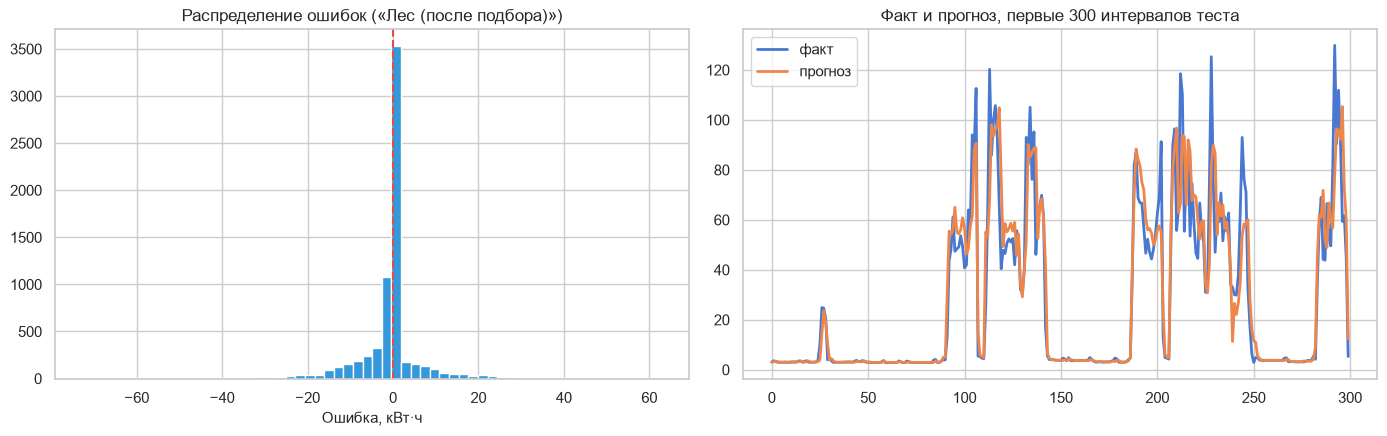


### Вывод по шагу 4: качество в деньгах и пиках

- MAE **3.97 кВт·ч ≈ 580 вон** на интервал.
- На пиках MAE 11.08 кВт·ч.
- **Оповещение о пике за 15 минут:** полнота **85%**,
  точность **74%**.
- **Прогноз оплачиваемого максимума мощности:**

| Месяц | Факт, кВт | Прогноз, кВт | Разрыв платы, млн вон |
|---|---|---|---|
| 2018-10 | 558 | 429 | 1.07 |
| 2018-11 | 629 | 486 | 1.19 |
| 2018-12 | 597 | 448 | 1.24 |

- Средний коэффициент занижения максимума **1.31** — им поправляем
  плановый максимум на шаге 5.


In [16]:
СРЕДНИЙ_ТАРИФ = 146.1
ТАРИФ_МОЩНОСТЬ = 8320.0
ПОРОГ_ПИКА = 60.0

y_pred = модель_лучшая.predict(X_te)
ошибки = y_te.values - y_pred
mae_общ = mean_absolute_error(y_te, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(ошибки, bins=60, color='#3498db', edgecolor='white')
axes[0].axvline(0, color='#e74c3c', ls='--')
axes[0].set_title(f'Распределение ошибок («{имя_лучшей}»)')
axes[0].set_xlabel('Ошибка, кВт·ч')
axes[1].plot(range(300), y_te.values[:300], lw=2, label='факт')
axes[1].plot(range(300), y_pred[:300], lw=2, label='прогноз')
axes[1].set_title('Факт и прогноз, первые 300 интервалов теста')
axes[1].legend()
plt.tight_layout(); plt.show()

маска_пика = y_te > ПОРОГ_ПИКА
тревога = y_pred > ПОРОГ_ПИКА
полнота = (тревога & маска_пика).sum() / маска_пика.sum()
точность = (тревога & маска_пика).sum() / max(тревога.sum(), 1)
mae_пик = mean_absolute_error(y_te[маска_пика], y_pred[маска_пика])

test = test.copy(); test['pred'] = y_pred
test['ym'] = test['date'].dt.to_period('M')
факт_макс = test.groupby('ym')['y'].max() * 4
прог_макс = test.groupby('ym')['pred'].max() * 4
коэф_макс = (факт_макс / прог_макс).mean()
разрыв = ((факт_макс - прог_макс).abs() * ТАРИФ_МОЩНОСТЬ)

табл_мес = "\n".join(f"| {m} | {факт_макс[m]:.0f} | {прог_макс[m]:.0f} | {разрыв[m]/1e6:.2f} |"
                     for m in факт_макс.index)
display(Markdown(f"""
### Вывод по шагу 4: качество в деньгах и пиках

- MAE **{mae_общ:.2f} кВт·ч ≈ {mae_общ*СРЕДНИЙ_ТАРИФ:.0f} вон** на интервал.
- На пиках MAE {mae_пик:.2f} кВт·ч.
- **Оповещение о пике за 15 минут:** полнота **{полнота*100:.0f}%**,
  точность **{точность*100:.0f}%**.
- **Прогноз оплачиваемого максимума мощности:**

| Месяц | Факт, кВт | Прогноз, кВт | Разрыв платы, млн вон |
|---|---|---|---|
{табл_мес}

- Средний коэффициент занижения максимума **{коэф_макс:.2f}** — им поправляем
  плановый максимум на шаге 5.
"""))

## Шаг 5: Прогноз на будущий период (01.01–07.01.2019)

**Пояснения:**
- **Рекурсивная цепочка:** прогноз интервала подставляется в лаги и скользящие,
  цепочка идёт на 672 шага вперёд.
- **Коридор неопределённости** — ±1,64 σ ошибки теста (≈90%).
- **Плановый максимум мощности** — прогноз × коэффициент занижения.

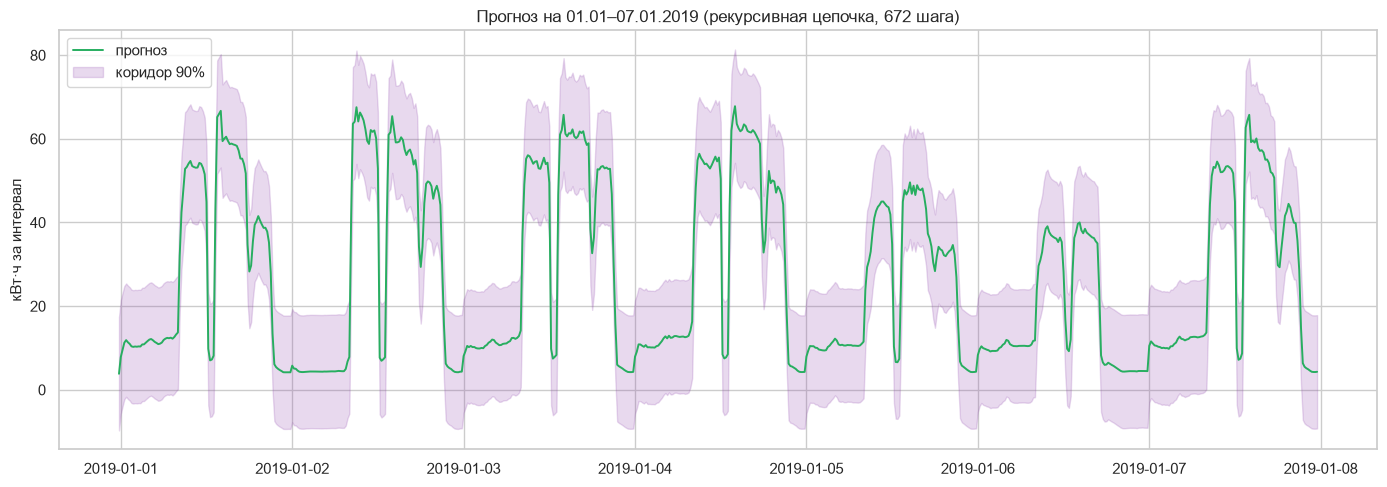


### Вывод по шагу 5: прогноз будущей недели для планировщика

| Показатель недели | Значение |
|---|---|
| Потребление | **18,574 кВт·ч** |
| Стоимость по зонам суток | **3.22 млн вон** |
| Доля пиковой зоны | **39%** |
| Плановый максимум мощности (с поправкой 1.31) | **355 кВт** |
| Плата за мощность при таком максимуме | **2.95 млн вон** |
| Коридор неопределённости (90%) | ±13.5 кВт·ч на интервал |

**По дням:**

| Дата | кВт·ч | Стоимость, млн вон | Максимум, кВт |
|---|---|---|---|
| 2018-12-31 | 4 | 0.00 | 15 |
| 2019-01-01 | 2,829 | 0.49 | 267 |
| 2019-01-02 | 2,859 | 0.51 | 270 |
| 2019-01-03 | 3,046 | 0.53 | 263 |
| 2019-01-04 | 3,056 | 0.53 | 271 |
| 2019-01-05 | 2,308 | 0.40 | 198 |
| 2019-01-06 | 1,649 | 0.28 | 160 |
| 2019-01-07 | 2,822 | 0.49 | 263 |

Файл `forecast_2019_week1.csv` передан планировщику переноса нагрузки.


In [17]:
ТАРИФ_2019 = {('Зима','Ночная'):82.3, ('Зима','Полупиковая'):143.8, ('Зима','Пиковая'):249.1}

def строка_признаков(ряд, даты, цель):
    """Признаки для прогноза интервала `цель` по истории `ряд` (последний = текущий)."""
    тек  = pd.Timestamp(даты[-1])     # защита от numpy.datetime64
    цель = pd.Timestamp(цель)
    h_cur  = тек.hour + тек.minute/60
    h_next = цель.hour + цель.minute/60
    return {'cur': ряд[-1], 'lag_1': ряд[-2], 'lag_4': ряд[-5],
            'lag_96': ряд[-97], 'lag_672': ряд[-673],
            'roll_mean_4': ряд[-4:].mean(), 'roll_std_4': ряд[-4:].std(ddof=1),
            'roll_mean_96': ряд[-96:].mean(),
            'hour_sin': np.sin(2*np.pi*h_cur/24), 'hour_cos': np.cos(2*np.pi*h_cur/24),
            'hour_next_sin': np.sin(2*np.pi*h_next/24), 'hour_next_cos': np.cos(2*np.pi*h_next/24),
            'is_weekend_next': int(цель.dayofweek >= 5),
            'zone_next': zone_of(цель), 'season_next': season_of(цель.month)}

def рекурсия(модель, даты_ист, ряд_ист, цели):
    ряд  = list(ряд_ист)
    даты = [pd.Timestamp(d) for d in даты_ист]   # вся история — в Timestamp
    ответ = []
    for цель in цели:
        x = pd.DataFrame([строка_признаков(np.array(ряд), даты, цель)])[FEATURES]
        p = max(модель.predict(x)[0], 0.0)
        ответ.append(p); ряд.append(p); даты.append(pd.Timestamp(цель))
    return np.array(ответ)

# ---------- Переобучаем лучшую модель на всех данных: меток будущего всё равно нет ----------
if имя_лучшей == 'CatBoost':
    модель_2019 = CatBoostRegressor(iterations=600, depth=8, learning_rate=0.05,
                                    random_seed=SEED, verbose=0)
    модель_2019.fit(df[FEATURES], df['y'], cat_features=CAT, verbose=0)
else:
    модель_2019 = clone(модель_лучшая)
    модель_2019.fit(df[FEATURES], df['y'])

# ---------- Цепочка на 672 шага вперёд ----------
цели_2019 = pd.date_range(df['date'].iloc[-1] + pd.Timedelta(minutes=15),
                          periods=672, freq='15min')
буд = рекурсия(модель_2019, df['date'].values, df['Usage_kWh'].values, цели_2019)

fut = pd.DataFrame({'date': цели_2019, 'прогноз_кВт_ч': буд})
fut['Зона']  = [zone_of(t) for t in fut['date']]
fut['Сезон'] = [season_of(t.month) for t in fut['date']]
fut['тариф'] = [ТАРИФ_2019[(s, z)] for s, z in zip(fut['Сезон'], fut['Зона'])]
fut['стоимость'] = fut['прогноз_кВт_ч'] * fut['тариф']
fut['кВт'] = fut['прогноз_кВт_ч'] * 4
fut['сутки'] = fut['date'].dt.date
fut.to_csv('forecast_2019_week1.csv', index=False)

нед_потреб = fut['прогноз_кВт_ч'].sum()
нед_стоим  = fut['стоимость'].sum()
пик_доля   = fut.loc[fut['Зона']=='Пиковая','прогноз_кВт_ч'].sum() / нед_потреб * 100
план_макс  = fut['кВт'].max() * коэф_макс
сигма = ошибки.std()

днев = fut.groupby('сутки').agg(кВт_ч=('прогноз_кВт_ч','sum'),
                                стоимость=('стоимость','sum'), макс_кВт=('кВт','max'))
табл_дн = "\n".join(f"| {d} | {r['кВт_ч']:,.0f} | {r['стоимость']/1e6:.2f} | {r['макс_кВт']:.0f} |"
                    for d, r in днев.iterrows())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(fut['date'], fut['прогноз_кВт_ч'], lw=1.4, color='#27ae60', label='прогноз')
ax.fill_between(fut['date'], fut['прогноз_кВт_ч'] - 1.64*сигма,
                fut['прогноз_кВт_ч'] + 1.64*сигма, alpha=0.2, color='#8e44ad',
                label='коридор 90%')
ax.set_title('Прогноз на 01.01–07.01.2019 (рекурсивная цепочка, 672 шага)')
ax.set_ylabel('кВт·ч за интервал'); ax.legend()
plt.tight_layout(); plt.show()

display(Markdown(f"""
### Вывод по шагу 5: прогноз будущей недели для планировщика

| Показатель недели | Значение |
|---|---|
| Потребление | **{нед_потреб:,.0f} кВт·ч** |
| Стоимость по зонам суток | **{нед_стоим/1e6:.2f} млн вон** |
| Доля пиковой зоны | **{пик_доля:.0f}%** |
| Плановый максимум мощности (с поправкой {коэф_макс:.2f}) | **{план_макс:.0f} кВт** |
| Плата за мощность при таком максимуме | **{план_макс*ТАРИФ_МОЩНОСТЬ/1e6:.2f} млн вон** |
| Коридор неопределённости (90%) | ±{1.64*сигма:.1f} кВт·ч на интервал |

**По дням:**

| Дата | кВт·ч | Стоимость, млн вон | Максимум, кВт |
|---|---|---|---|
{табл_дн}

Файл `forecast_2019_week1.csv` передан планировщику переноса нагрузки.
"""))

## Шаг 6: Сценарный расчёт до 2030 года

**Почему не ML-прогноз:** на горизонте лет модель 15-минутных интервалов
теряет информативность (ошибка рекурсии накапливается, структура ряда
нестационарна). Стратегические горизонты считают сценарными моделями
с явными допущениями.

**Что делаем:**
1. **Три сценария:** пессимистичный / базовый / оптимистичный — отличаются
   ростом производства, энергоэффективностью и индексацией тарифов.
2. **Меры экономии** (подтверждённые бизнес-разбором): −6,8% стоимости
   с года внедрения.
3. **Чувствительность накопленной экономии** к каждому допущению:
   торнадо-диаграмма показывает, какие рычаги самые важные для заказчика.

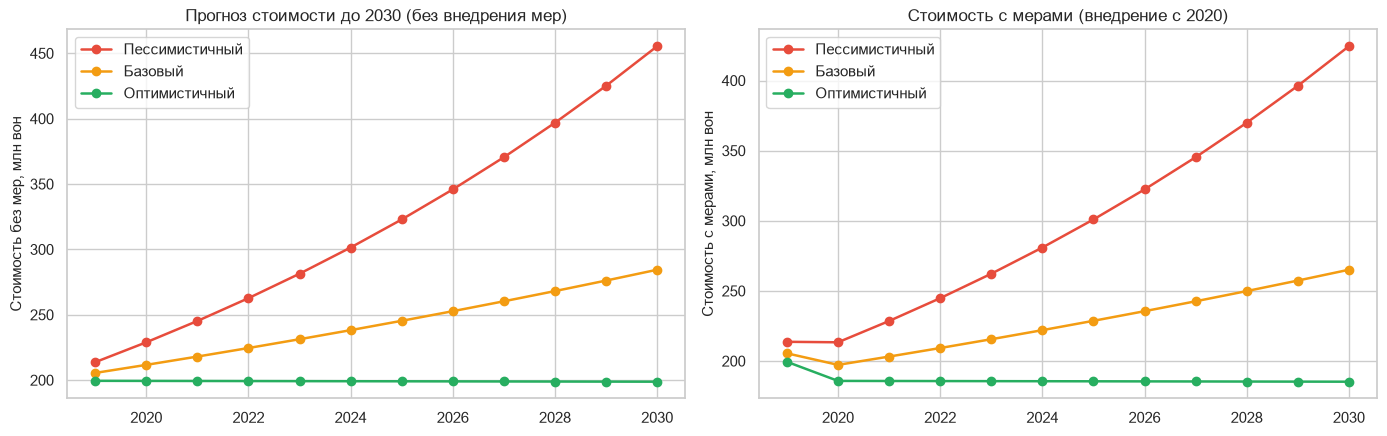

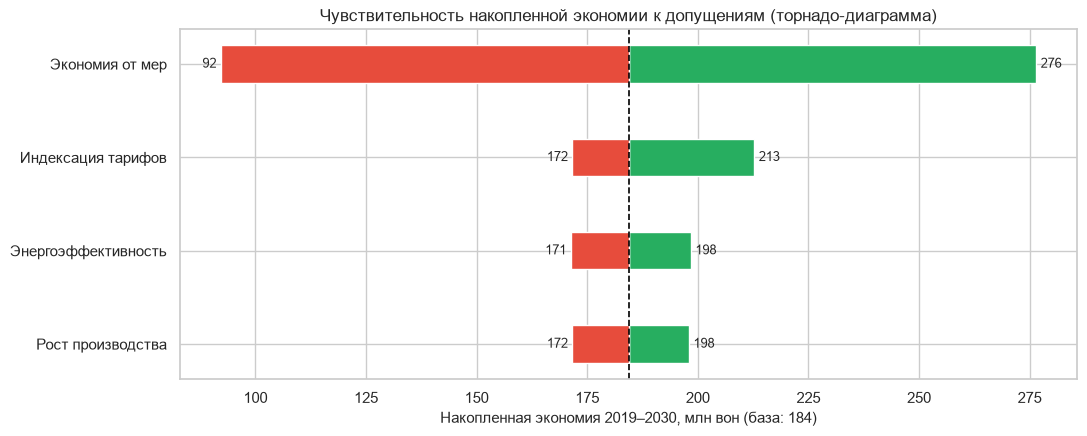


### Вывод по шагу 6: стратегия до 2030 года

**Сравнение трёх сценариев** (накопленная экономия за 2019–2030 от внедрения
подтверждённых мер с 2020 года):

| Сценарий | Потребление 2030, кВт·ч | Стоимость без мер, млн вон | С мерами, млн вон | CO₂ 2030, т | Накопленная экономия, млн вон |
|---|---|---|---|---|---|
| Пессимистичный | 1,368,213 | 455 | 424 | 575 | 247 |
| Базовый | 1,078,776 | 284 | 265 | 453 | 184 |
| Оптимистичный | 848,548 | 199 | 185 | 356 | 149 |

**Чувствительность накопленной экономии** к каждому допущению
(низкое значение → базовое → высокое):

| Допущение | Низкое | Базовое | Высокое | Размах |
|---|---|---|---|---|
| Рост производства | 172 | 184 | 198 | 26 |
| Энергоэффективность | 171 | 184 | 198 | 27 |
| Индексация тарифов | 172 | 184 | 213 | 41 |
| Экономия от мер | 92 | 184 | 276 | 184 |

- Самый мощный рычаг — **экономия от мер**: её размах на торнадо-диаграмме
  шире остальных, то есть полнота внедрения рекомендаций бизнес-разбора
  важнее внешних факторов.
- Второй по силе — **индексация тарифов**: при ускоренной индексации
  внедрение мер становится ещё выгоднее.
- Рост производства и энергоэффективность влияют умеренно и в разные стороны:
  при росте увеличивается и база счёта, и абсолютная экономия.
- Формулировка для защиты: «ML-модель работает на горизонте до суток,
  недельное планирование — на сезонном профиле, стратегия до 2030 года —
  на сценарной модели с явными допущениями. Накопленная экономия в базовом
  сценарии — **184 млн вон**, разброс по сценариям —
  от **247** (пессимистичный) до **149 млн вон** (оптимистичный)».


In [18]:
ИНТЕНСИВНОСТЬ_CO2 = 0.00042
БАЗА_КВТЧ = 959_637.0
БАЗА_ВОН  = 199_500_000.0
ГОД_ВНЕДРЕНИЯ_МЕР = 2020
ДОЛЯ_ЭКОНОМИИ_МЕР = 0.068
ГОДЫ = list(range(2019, 2031))

def сценарий(доп, доля_мер=ДОЛЯ_ЭКОНОМИИ_МЕР):
    """Расчёт по годам при заданных допущениях; долю экономии можно менять."""
    строки, накоп = [], 0.0
    for n, год in enumerate(ГОДЫ, start=1):
        кВтч = БАЗА_КВТЧ * ((1+доп['рост'])*(1+доп['ээф']))**n
        без_мер = БАЗА_ВОН * ((1+доп['рост'])*(1+доп['ээф'])*(1+доп['инд']))**n
        с_мерами = без_мер * (1 - доля_мер) if год >= ГОД_ВНЕДРЕНИЯ_МЕР else без_мер
        накоп += без_мер - с_мерами
        строки.append((год, кВтч, без_мер, с_мерами, кВтч*ИНТЕНСИВНОСТЬ_CO2))
    return pd.DataFrame(строки, columns=['год','кВт_ч','без_мер','с_мерами','CO2_т']), накоп

# ---------- Три сценария ----------
сц = {
    'Пессимистичный': {'рост': 0.03, 'ээф':  0.00, 'инд': 0.04},
    'Базовый':        {'рост': 0.02, 'ээф': -0.01, 'инд': 0.02},
    'Оптимистичный':  {'рост': 0.01, 'ээф': -0.02, 'инд': 0.01},
}
табл_сц, итоги = {}, {}
for имя, доп in сц.items():
    df_сц, накоп = сценарий(доп)
    табл_сц[имя] = df_сц
    итоги[имя] = {'потребление_2030': df_сц.iloc[-1]['кВт_ч'],
                  'стоимость_2030':  df_сц.iloc[-1]['без_мер'],
                  'с_мерами_2030':   df_сц.iloc[-1]['с_мерами'],
                  'CO2_2030':        df_сц.iloc[-1]['CO2_т'],
                  'накопленная_экономия': накоп}

# ---------- Графики сценариев ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
цвета = {'Пессимистичный':'#e74c3c','Базовый':'#f39c12','Оптимистичный':'#27ae60'}
for имя in сц:
    axes[0].plot(табл_сц[имя]['год'], табл_сц[имя]['без_мер']/1e6,
                 marker='o', color=цвета[имя], label=имя, lw=1.8)
axes[0].set_ylabel('Стоимость без мер, млн вон')
axes[0].set_title('Прогноз стоимости до 2030 (без внедрения мер)')
axes[0].legend()
for имя in сц:
    axes[1].plot(табл_сц[имя]['год'], табл_сц[имя]['с_мерами']/1e6,
                 marker='o', color=цвета[имя], label=имя, lw=1.8)
axes[1].set_ylabel('Стоимость с мерами, млн вон')
axes[1].set_title(f'Стоимость с мерами (внедрение с {ГОД_ВНЕДРЕНИЯ_МЕР})')
axes[1].legend()
plt.tight_layout(); plt.show()

табл_итогов = "\n".join(
    f"| {имя} | {ит['потребление_2030']:,.0f} | {ит['стоимость_2030']/1e6:,.0f} | "
    f"{ит['с_мерами_2030']/1e6:,.0f} | {ит['CO2_2030']:,.0f} | "
    f"{ит['накопленная_экономия']/1e6:,.0f} |"
    for имя, ит in итоги.items())

# ---------- Чувствительность: варьируем каждое допущение ----------
баз = сц['Базовый'].copy()
баз_млн = итоги['Базовый']['накопленная_экономия'] / 1e6

чувств = {}
вариации = {
    'Рост производства':   [('рост', 0.01), ('рост', 0.03)],
    'Энергоэффективность': [('ээф', -0.02), ('ээф', 0.00)],
    'Индексация тарифов':  [('инд', 0.01), ('инд', 0.04)],
}
for парам, пара_знач in вариации.items():
    значения = []
    for ключ, знач in пара_знач:
        доп = баз.copy(); доп[ключ] = знач
        _, накоп = сценарий(доп)
        значения.append(накоп / 1e6)
    чувств[парам] = (значения[0], значения[1], значения[1] - значения[0])

# Отдельно — доля экономии от мер: половина и полторы от базовых 6,8%
экон_низкая  = ДОЛЯ_ЭКОНОМИИ_МЕР / 2      # 3,4%
экон_высокая = ДОЛЯ_ЭКОНОМИИ_МЕР * 1.5    # 10,2%
значения_мер = []
for доля in [экон_низкая, экон_высокая]:
    _, накоп = сценарий(баз, доля_мер=доля)
    значения_мер.append(накоп / 1e6)
чувств['Экономия от мер'] = (значения_мер[0], значения_мер[1],
                             значения_мер[1] - значения_мер[0])

# ---------- Торнадо-диаграмма ----------
fig, ax = plt.subplots(figsize=(11, 4.5))
параметры = list(чувств.keys())
for i, парам in enumerate(параметры):
    низ, верх, _ = чувств[парам]
    ax.barh(i, верх - баз_млн, left=баз_млн, color='#27ae60', height=0.4)
    ax.barh(i, низ - баз_млн, left=баз_млн, color='#e74c3c', height=0.4)
    ax.text(верх + 1, i, f'{верх:.0f}', va='center', fontsize=9)
    ax.text(низ - 1, i, f'{низ:.0f}', va='center', ha='right', fontsize=9)
ax.set_yticks(range(len(параметры))); ax.set_yticklabels(параметры)
ax.axvline(баз_млн, color='black', ls='--', lw=1.2)
ax.set_xlabel(f'Накопленная экономия 2019–2030, млн вон (база: {баз_млн:.0f})')
ax.set_title('Чувствительность накопленной экономии к допущениям (торнадо-диаграмма)')
plt.tight_layout(); plt.show()

табл_чувств = "\n".join(
    f"| {парам} | {чувств[парам][0]:,.0f} | {баз_млн:,.0f} | {чувств[парам][1]:,.0f} | "
    f"{чувств[парам][2]:,.0f} |"
    for парам in параметры)

песс = итоги['Пессимистичный']['накопленная_экономия'] / 1e6
опт  = итоги['Оптимистичный']['накопленная_экономия'] / 1e6

display(Markdown(f"""
### Вывод по шагу 6: стратегия до 2030 года

**Сравнение трёх сценариев** (накопленная экономия за 2019–2030 от внедрения
подтверждённых мер с {ГОД_ВНЕДРЕНИЯ_МЕР} года):

| Сценарий | Потребление 2030, кВт·ч | Стоимость без мер, млн вон | С мерами, млн вон | CO₂ 2030, т | Накопленная экономия, млн вон |
|---|---|---|---|---|---|
{табл_итогов}

**Чувствительность накопленной экономии** к каждому допущению
(низкое значение → базовое → высокое):

| Допущение | Низкое | Базовое | Высокое | Размах |
|---|---|---|---|---|
{табл_чувств}

- Самый мощный рычаг — **экономия от мер**: её размах на торнадо-диаграмме
  шире остальных, то есть полнота внедрения рекомендаций бизнес-разбора
  важнее внешних факторов.
- Второй по силе — **индексация тарифов**: при ускоренной индексации
  внедрение мер становится ещё выгоднее.
- Рост производства и энергоэффективность влияют умеренно и в разные стороны:
  при росте увеличивается и база счёта, и абсолютная экономия.
- Формулировка для защиты: «ML-модель работает на горизонте до суток,
  недельное планирование — на сезонном профиле, стратегия до 2030 года —
  на сценарной модели с явными допущениями. Накопленная экономия в базовом
  сценарии — **{баз_млн:,.0f} млн вон**, разброс по сценариям —
  от **{песс:,.0f}** (пессимистичный) до **{опт:,.0f} млн вон** (оптимистичный)».
"""))

## Ограничения и следующие шаги

**Ограничения:**
- Ошибка рекурсивной цепочки растёт с горизонтом: недельные цифры для
  планирования, не для оперативных оповещений.
- Точечный прогноз занижает пики: плановый максимум поправлен коэффициентом.
- Сценарный расчёт — не прогноз, а модель с явными допущениями: результат
  зависит от выбора допущений, чувствительность показана.
- Календарь 2019–2030 не учитывает праздники и ремонты.
- Проверка возможна только на исторических данных: меток 2019+ нет.

**Следующие шаги:**
1. Квантильный прогноз (90-й процентиль) для планового максимума мощности.
2. Многогоризонтная модель (1–4 часа) для планировщика запусков.
3. Скользящий пересчёт цепочки по мере поступления факта.
4. Интеграция сценарной модели в панель показателей заказчика.

## Контрольная ячейка

Печатает ключевые числа файла в одном месте — для сверки с выводами выше
и для переноса в слайды защиты.

In [19]:
print("===== ЧИСЛА ДЛЯ ОТЧЁТА И СЛАЙДОВ =====")
print(f"Наблюдений после признаков:      {len(df):,}")
print(f"MAE наивного прогноза:           {m_naive[0]:.2f} кВт·ч")
print(f"MAE лучшей модели ({имя_лучшей}): {mae_общ:.2f} кВт·ч (~{mae_общ*СРЕДНИЙ_ТАРИФ:.0f} вон/интервал)")
print(f"Полнота / точность оповещения:   {полнота*100:.0f}% / {точность*100:.0f}%")
print(f"Коэффициент занижения максимума: {коэф_макс:.2f}")
print(f"Прогноз недели 2019:             {нед_потреб:,.0f} кВт·ч, {нед_стоим/1e6:.2f} млн вон")
print(f"Плановый максимум мощности:      {план_макс:.0f} кВт")
print(f"\n--- СЦЕНАРИИ ДО 2030 ---")
for имя, итог in итоги.items():
    print(f"  {имя:17s}: накопл. экономия {итог['накопленная_экономия']/1e6:,.0f} млн вон, "
          f"стоимость 2030 {итог['стоимость_2030']/1e6:,.0f} млн вон")
print(f"\n--- ЧУВСТВИТЕЛЬНОСТЬ (размах, млн вон) ---")
for парам in чувств:
    print(f"  {парам:25s}: размах {чувств[парам][2]:,.0f} млн вон")
print("\nСкопируй значения в презентацию после успешного Run All.")

===== ЧИСЛА ДЛЯ ОТЧЁТА И СЛАЙДОВ =====
Наблюдений после признаков:      34,367
MAE наивного прогноза:           5.47 кВт·ч
MAE лучшей модели (Лес (после подбора)): 3.97 кВт·ч (~580 вон/интервал)
Полнота / точность оповещения:   85% / 74%
Коэффициент занижения максимума: 1.31
Прогноз недели 2019:             18,574 кВт·ч, 3.22 млн вон
Плановый максимум мощности:      355 кВт

--- СЦЕНАРИИ ДО 2030 ---
  Пессимистичный   : накопл. экономия 247 млн вон, стоимость 2030 455 млн вон
  Базовый          : накопл. экономия 184 млн вон, стоимость 2030 284 млн вон
  Оптимистичный    : накопл. экономия 149 млн вон, стоимость 2030 199 млн вон

--- ЧУВСТВИТЕЛЬНОСТЬ (размах, млн вон) ---
  Рост производства        : размах 26 млн вон
  Энергоэффективность      : размах 27 млн вон
  Индексация тарифов       : размах 41 млн вон
  Экономия от мер          : размах 184 млн вон

Скопируй значения в презентацию после успешного Run All.
